# Reproducing example (trumpet mutes) from *Ravel*.

An example from the opening of La danse des jeunes filles in Ravel’s
*Daphnis and Chlo´e* is used to illustrate how simply examining sounds in the bank can assist composersin their orchestration decisions. 

In *Daphnis et Chlo´e*, Ravel uses a fascinating counterpoint of
timbres at the beginning of *La danse des jeunes
filles*, at rehearsal number 17. In the foreground,
a solo muted trumpet is answered one measure
later by the second oboe and English horn in octave
doubling, with the first oboe and the E-flat clarinet,
as shown in Figure 1a. (The transcription is in
concert pitch.) 

It seems clear that Ravel is using
the woodwinds to imitate the sound of the muted
trumpet. 

<img src='../Imgs/ravel_la_danse.JPG' alt='Section from the score of La Danse ds juene filles by Ravel'>

We have used the tool to analyze the sound
of the woodwind instruments and to determine
which trumpet mute would be best suited to imitate
it. The indication *con sordino* in a trumpet’s part is
almost always read as “straight mute on.”

We show that the correct mute for the trumpet should be the *Cup Mute*.

---

### Splitting the Trumpet mute sound files

#### Transposing

Original score: Db5 (C#5)  
- We have Trumpet mutes (straight and cup): C5

We need to transpose the everything else:  
- Oboe, English Horn, and Clarinet down a 1/2 step.

Originals  
- Oboes:  Db5 (C#5), Db6 (C#6)  
- English Horn: Db5 (C#5)  
- Clarinet in Eb: Db6 (C#6)  
- Muted trumpet: Db5  

Transposed:  
- Oboes:  C5, C6  
- English Horn: C5  
- Clarinet in Eb: C6  
- Muted trumpet: C5  

Muted trumpets are in the audio file: "`5 Track 05.aiff`".  
C5 is the 3rd sound in the file.

---

We have the Oboes, English Horn, and Clarinet sounds at these pitches.  

So, we need to read in the *muted trumpet* sounds from the Google folder that Francois uploaded with muted trumpet sounds, and extract the individual pitches.

Like before, we use the `PyDub` library, and follow:

from: https://stackoverflow.com/questions/37725416/pydub-combine-split-on-silence-with-minimum-length-file-size

### Read in trumpet mute sounds.

#### Get trumpet strait mute C5

In [1]:
from pydub import AudioSegment
from pydub.silence import split_on_silence

trpstr_sounds = AudioSegment.from_file("../MiscSounds/Trumpet-mutes_Basson-multiphics/5 Track 05.aiff")

trpstr_chunks = split_on_silence(
   trpstr_sounds,
    # split on silences longer than 1000ms (1 sec)
    min_silence_len=500,
    # anything under -50 dBFS is considered silence
    silence_thresh=-50, 
    # keep 200 ms of leading/trailing silence
    keep_silence=100
)

In [2]:
trpstr_sounds.dBFS

-32.225511333511086

Number of sound segments split

In [3]:
len(trpstr_chunks)

6

Play one of the segments

In [4]:
trpstr_chunks[2]

In [5]:
trp_str_C5 = trpstr_chunks[2]

#### Cup Mute

In [6]:
trpcup_sounds = AudioSegment.from_file("../MiscSounds/Trumpet-mutes_Basson-multiphics/11 Track 11.aiff")

trpcup_chunks = split_on_silence(
   trpcup_sounds,
    # split on silences longer than 1000ms (1 sec)
    min_silence_len=500,
    # anything under -50 dBFS is considered silence
    silence_thresh=-50, 
    # keep 200 ms of leading/trailing silence
    keep_silence=100
)

In [7]:
len(trpstr_chunks)

6

In [8]:
trp_cup_C5 = trpcup_chunks[2]

In [11]:
trp_str_C5

In [10]:
trp_cup_C5

---

## FFTs

In [12]:
from scipy.fftpack import fft, ifft

In [13]:
shave_percent = 0.15
hamwin = np.hamming(4096)

### make_fft()

In [14]:
def make_fft(sound, shave=0.15):

    """Arguments:
    
    \'sound\': sound to transform (created by pydub)
    \'shave\': fraction of beginning and end to delete before computing FFT.
    
    """

    # get 1 channel
    sound = sound.set_channels(1)
    
    sounddata = sound.get_array_of_samples()
    soundlen = len(sounddata)
    begin = np.int(shave * soundlen)
    end = np.int((1 - shave) * soundlen)
    
    n = 0
    xf_ave = np.zeros(2048)

    # Average over blocks of size 4096 
    for i in range(begin, end-4096, 512):
        x = sounddata[i:i+4096]
        x = x * hamwin
        xf = fft(x)
        xf_ave += (np.absolute(xf)**2)[:2048]
#        xf_ave += (xf**2)[:2048]
        n+=1
    
    xf_ave = np.sqrt(xf_ave)/n    

    # normalize
    xf_ave /= xf_ave.sum()
    return xf_ave

In [15]:
fft_trp_str_C5 = make_fft(trp_str_C5)

In [16]:
fft_trp_cup_C5 = make_fft(trp_cup_C5)

In [17]:
fft_trp_ord_C5 = np.loadtxt('../Soundbank_McGill/FFTBank_WB/tpc-c5-ord-mf.txt')

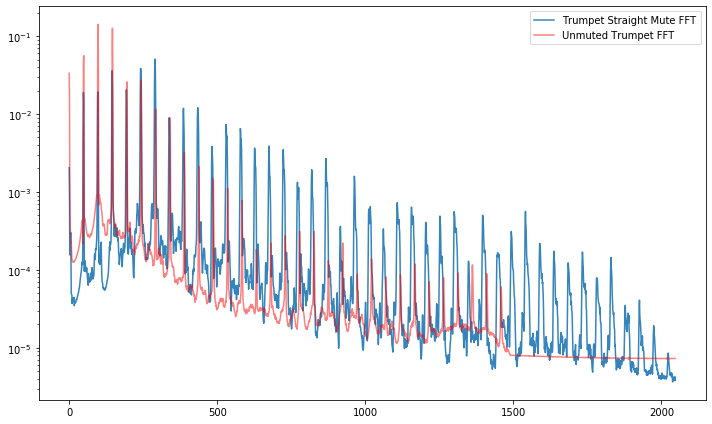

In [18]:
%matplotlib inline

plt.figure(figsize=(10,6))

#plt.subplot(2, 1, 1)
plt.plot(range(2048), fft_trp_str_C5[:2048], alpha=0.9, label="Trumpet Straight Mute FFT")
#plt.yscale('log')
#plt.legend()

#plt.subplot(2, 1, 2)
plt.plot(range(2048), fft_trp_ord_C5[:2048], alpha=0.5, label="Unmuted Trumpet FFT", color='red')
plt.yscale('log')
plt.legend()


plt.tight_layout()

Figure 1b
shows two average spectra. The top is an averaged
spectrum of a trumpet playing a D-flat5 mezzo-forte
(554 Hz), muted with a straight mute. The bottom
graphic is an averaged spectrum of an unmuted
trumpet playing the same pitch and dynamic. 

A comparison of these two spectra shows that the
straight mute behaves like a high-pass filter.  
Actually, the straight mute adds a significant amount of hight frequency partials.

---

## Read obeo, clarinet FFTs / sounds

### Compare FFTs

In [19]:
fft_obo_c5_ord_mf = np.loadtxt('../Soundbank_McGill/FFTBank_WB/obo-c5-ord-mf.txt')

In [20]:
fft_obo_c6_ord_mf = np.loadtxt('../Soundbank_McGill/FFTBank_WB/obo-c6-ord-mf.txt')

In [21]:
fft_enh_c5_ord_mf = np.loadtxt('../Soundbank_McGill/FFTBank_WB/enh-c5-ord-mf.txt')

In [22]:
fft_cle_c6_ord_mf = np.loadtxt('../Soundbank_McGill/FFTBank_WB/cle-c6-ord-mf.txt')

In [23]:
fft_ooc = fft_obo_c5_ord_mf + fft_obo_c6_ord_mf + fft_cle_c6_ord_mf + fft_enh_c5_ord_mf
fft_ooc /= fft_ooc.sum()

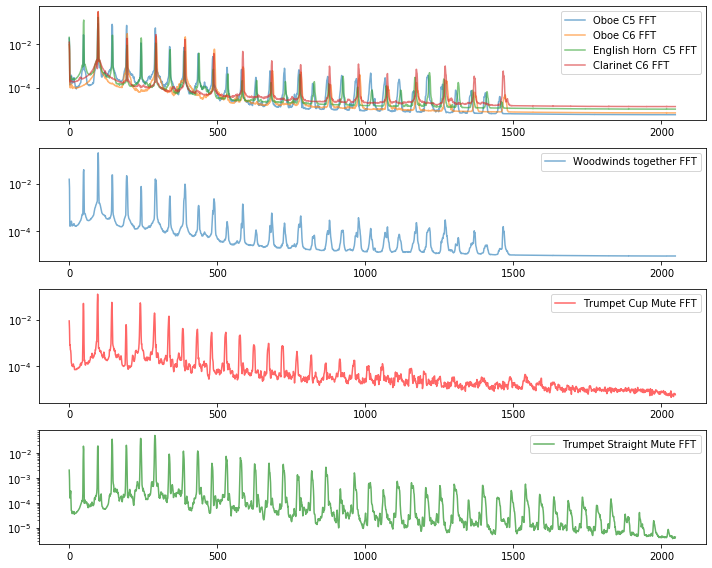

In [24]:
%matplotlib inline

plt.figure(figsize=(10,8))

plt.subplot(4, 1, 1)
plt.plot(range(2048), fft_obo_c5_ord_mf[:2048], alpha=0.6, label="Oboe C5 FFT")
plt.plot(range(2048), fft_obo_c6_ord_mf[:2048], alpha=0.6, label="Oboe C6 FFT")
plt.plot(range(2048), fft_enh_c5_ord_mf[:2048], alpha=0.6, label="English Horn  C5 FFT")
plt.plot(range(2048), fft_cle_c6_ord_mf[:2048], alpha=0.6, label="Clarinet C6 FFT")
plt.yscale('log')
plt.legend()

plt.subplot(4, 1, 2)
plt.plot(range(2048), fft_ooc[:2048], alpha=0.6, label="Woodwinds together FFT")
plt.yscale('log')
plt.legend()

plt.subplot(4, 1, 3)
plt.plot(range(2048), fft_trp_cup_C5[:2048], color='r', alpha=0.6, label="Trumpet Cup Mute FFT")
plt.yscale('log')
plt.legend()

plt.subplot(4, 1, 4)
plt.plot(range(2048), fft_trp_str_C5[:2048], color='g', alpha=0.6, label="Trumpet Straight Mute FFT")
plt.yscale('log')
plt.legend()


plt.tight_layout()

Figure 3 shows three averaged spectra. The top
is again the spectrum of a trumpet playing a D-flat5
mezzo-forte, muted with a straight mute, and the
middle spectrum shows the mixture of the four
woodwind instruments. Note that the main energy
is located in its lower part, more specifically around
its second partial (D-flat6; 1,109 Hz), and that there
is a cut-off around the 16th partial. 

This spectrum
does not correspond very well with the one using the
straight mute, which has its main energy around the
5th partial (F7; 2,794 Hz) and has an extremely rich
structure, including more than 25 partials. 

On the
other hand, the last spectrum in Figure 1c displays
the sound of a trumpet muted with a cup mute,
playing a D-flat5 mezzo-forte. Note that in this
case, the main energy is around the second partial,
and that there is a cut-off around the 12th partial.

Therefore, we suggest that the resemblance between
the trumpet’s sound and the four woodwind instruments
would be enhanced if the trumpet were to be
muted with a cup mute instead of a straight mute.

#### Combined woodwind chord

In [25]:
chord_list = ['../Soundbank_McGill/Soundbank_WB/obo-c5-ord-mf.aif',
              '../Soundbank_McGill/Soundbank_WB/obo-c6-ord-mf.aif',
              '../Soundbank_McGill/Soundbank_WB/enh-c5-ord-mf.aif',
              '../Soundbank_McGill/Soundbank_WB/cle-c6-ord-mf.aif'
             ]

In [26]:
combined = AudioSegment.from_file(chord_list[0]) - 10

for s in chord_list[1:]:
    sound = AudioSegment.from_file(s)
    combined = combined.overlay(sound -10)

In [27]:
combined.dBFS

-28.608882502103118

### Compare!

In [28]:
combined

In [111]:
(trp_cup_C5 - 8).dBFS

-44.508306471944

In [29]:
trp_cup_C5 - 8

In [30]:
trp_str_C5 - 8

The trumpet with cup mute is much "closer".